### The Solar Sentinel

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.rcParams["figure.figsize"] = (40,3)


In [13]:
SRC, DST = "omni_all.csv", Path("omni_1995.parquet")
parts = []
for chunk in pd.read_csv(SRC, parse_dates=["time"], chunksize=2_000_000):
    chunk = chunk[chunk["time"] >= "1995-01-01"]
    if len(chunk):
        parts.append(chunk)

df = (pd.concat(parts)
        .drop_duplicates("time")
        .sort_values("time")
        .set_index("time"))

# Drop padded future rows in the current year: keep up to the last row with any solar wind data
last_valid = df["bz_gsm"].last_valid_index()
df = df.loc[:last_valid]

df = df.astype("float32")
df.to_parquet(DST, compression="zstd")

print(df.shape, f"{DST.stat().st_size/1e6:.0f} MB")
print(df.index.is_monotonic_increasing, df.index.duplicated().sum())
print("last row with data:", last_valid)
print(df.describe().T[["count", "min", "max"]])

(16738594, 21) 423 MB
True 0
last row with data: 2026-10-29 00:33:00
                  count           min           max
timeshift_s  15567549.0 -10797.000000  1.079800e+04
b_mag        15567549.0      0.120000  7.291000e+01
bx_gsm       15567549.0    -49.509998  3.995000e+01
by_gsm       15567549.0    -64.790001  6.990000e+01
bz_gsm       15567549.0    -60.590000  6.970000e+01
speed        13300082.0    180.699997  1.137400e+03
density      13300082.0      0.030000  8.095000e+01
temp         13291347.0    543.000000  7.617800e+06
pressure     13355387.0      0.010000  9.620000e+01
e_field      13265503.0    -68.160004  6.425000e+01
ae           16734240.0      1.000000  4.366000e+03
al           16734240.0  -4342.000000  1.480000e+02
au           16734240.0   -975.000000  2.063000e+03
sym_h        16738594.0   -518.000000  1.510000e+02
asy_h        16738594.0      0.000000  9.840000e+02
pc_n         15755697.0    -64.180000  3.638000e+01
kp           16738594.0      0.000000  9.000000

In [14]:
df["b_sum"] = ((df["bx_gsm"]**2 + df["by_gsm"]**2 + df["bz_gsm"]**2)) ** (0.5)

In [15]:
# todo: add slope for b_sum, pressure, density, speed and temperature
df["pressure_slope"] = df["pressure"].diff() / df.index.to_series().diff().dt.total_seconds().div(3600)
df["density_slope"] = df["density"].diff() / df.index.to_series().diff().dt.total_seconds().div(3600)
df["speed_slope"] = df["speed"].diff() / df.index.to_series().diff().dt.total_seconds().div(3600)
df["temp_slope"] = df["temp"].diff() / df.index.to_series().diff().dt.total_seconds().div(3600)

<Axes: xlabel='time', ylabel='kp'>

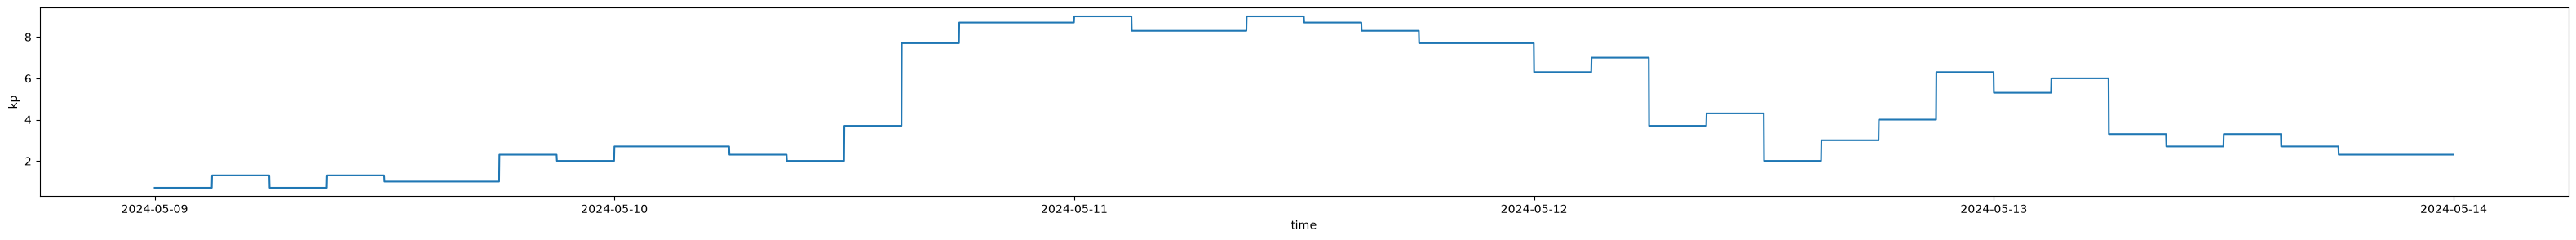

In [16]:
df_2024 = df.loc["2024-05-09":"2024-05-13"]
sns.lineplot(df_2024, x = "time", y = "kp" )